# Deep Learning Model Training for Customer Sentiment Analysis


In this walkthrough, you will train and fine-tune a deep learning model to analyze customer feedback and provide actionable insights.

**Scenario:**
Your retail client needs a sentiment analysis model to categorize customer reviews as positive, neutral, or negative and identify trends to enhance their strategy.

**Objective:**
- Preprocess a synthetic dataset of customer reviews for model training.
- Train a sentiment analysis model using an LSTM or fine-tune a pre-trained transformer like BERT.
- Measure accuracy, F1-score, and confusion matrix; identify areas for improvement.
- Deliver a brief summary of key trends, model performance, and recommendations (e.g., addressing delivery complaints).
- Discuss how to explain findings and next steps to a non-technical client.




### Part 1: Load the 'product_reviews.csv' dataset into a pandas DataFrame

In this section, we'll load the customer reviews dataset and perform exploratory data analysis to understand the distribution of sentiments and prepare the data for model training.

In [1]:
# TODO: Import pandas library
import pandas as pd

In [4]:
# TODO: Load the product reviews dataset using pd.read_csv()
data=pd.read_csv('./data/prod_reviews.csv')

In [5]:
# TODO: Display the first 10 rows using head(10)
data.head(10)

,Review,Sentiment
0,This product exceeded my expectations! It's hi...,Positive
1,"The product was decent. It worked fine, but it...",Neutral
2,I had a terrible experience with this company....,Negative
3,It's an okay product. Nothing to write home ab...,Neutral
4,Disappointed with the product. It didn't meet ...,Negative
5,Avoid this company at all costs. The service i...,Negative
6,I had a terrible experience with this company....,Negative
7,Avoid this company at all costs. The service i...,Negative
8,This product exceeded my expectations! It's hi...,Positive
9,This product is outstanding! It's exactly what...,Positive


In [6]:
data.describe()

,Review,Sentiment
count,395,395
unique,140,3
top,Fantastic customer service! The representative...,Positive
freq,22,138


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     395 non-null    object
 1   Sentiment  395 non-null    object
dtypes: object(2)
memory usage: 6.3+ KB


In [8]:
data["Sentiment"].value_counts()

Positive    138
Negative    129
Neutral     128
Name: Sentiment, dtype: int64

In [11]:
import matplotlib
if not hasattr(matplotlib.rcParams, '_get'): 
    matplotlib.rcParams._get = lambda key: matplotlib.rcParams.get(key)
import matplotlib.pyplot as plt 

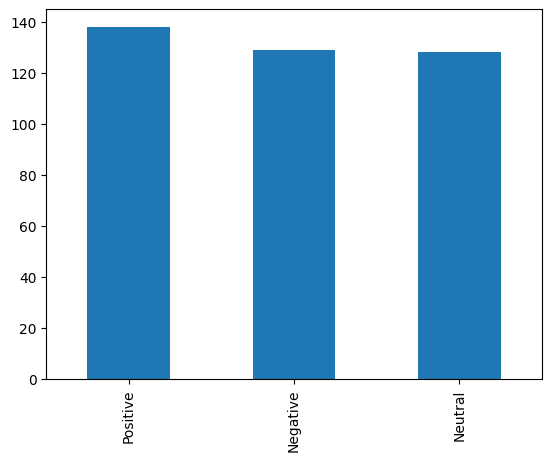

In [14]:
# TODO: Create a bar plot to visualize sentiment distribution
data["Sentiment"].value_counts().plot(kind='bar')
plt.show()

In [13]:
# TODO: Display the plot using plt.show()

**Data Preprocessing**

Now we'll clean and preprocess the text data to prepare it for the LSTM model. Raw text data contains many elements that can interfere with machine learning models, such as HTML tags, special characters, numbers, and common words (stopwords) that don't carry meaningful sentiment information. We are creating a function called clean_reviews() that will systematically remove these unwanted elements and standardize the text format. This preprocessing step is crucial because clean, consistent text data leads to better model performance and more accurate sentiment predictions.

In [15]:
# TODO: Import re for regular expressions
# TODO: Import nltk for natural language processing
# TODO: Import stopwords and word_tokenize from nltk
# TODO: Import tensorflow for deep learning
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import tensorflow as tf


2026-10-20 20:45:51.993842: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-20 20:45:52.132855: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-20 20:45:52.682164: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 20:45:52.682216: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 20:45:52.771336: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

In [16]:
# TODO: Import train_test_split from sklearn
# TODO: Import Tokenizer and pad_sequences from keras preprocessing
# TODO: Import to_categorical for one-hot encoding
# TODO: Import Sequential and LSTM layers from keras
from sklearn.model_selection import train_test_split
import sklearn

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional


In [17]:
# TODO: Download punkt tokenizer models using nltk.download()
# TODO: Download stopwords using nltk.download()
# TODO: Create a set of English stopwords
nltk.download('punkt')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [18]:
# TODO: Define a clean_reviews function that takes text as parameter
# TODO: - Remove HTML tags and brackets using regex compile and sub
# TODO: - Remove special characters (@, #, $, etc) using pattern matching
# TODO: - Remove all numbers from the text using regex pattern
# TODO: - Convert entire text to lowercase for consistency
# TODO: - Tokenize the text into individual words using word_tokenize
# TODO: - Filter out stopwords to keep only meaningful words
# TODO: - Return the cleaned and tokenized text

# Review text Cleaning
def clean_reviews(text):
    
    # removing html brackets and other square brackets from the string using regex
    regex = re.compile('<.*?>') # r'<.*?>'
    text = re.sub(regex, '', text)

    # removing special characters like @, #, $, etc
    pattern = re.compile('[^a-zA-z0-9\s]')
    text = re.sub(pattern,'',text)

    # removing numbers
    pattern = re.compile('\d+')
    text = re.sub(pattern,'',text)

    # converting text to lower case
    text = text.lower()
    
    # Tokenization of words
    text = word_tokenize(text)
    
    # Stop words removal
    text = [word for word in text if not word in stop_words]
    
    return ' '.join(text)

In [19]:
# TODO: Apply the clean_reviews function to the Review column
data['Review'] = data['Review'].apply(clean_reviews)
# TODO: Extract reviews and sentiments arrays from the dataset
reviews = data['Review'].values
sentiments = data['Sentiment'].values
# TODO: Create a sentiment_labels dictionary mapping sentiments to integers
sentiment_labels = {'Positive': 0, 'Neutral': 1, 'Negative': 2}

# TODO: Encode sentiment labels into numerical format using list comprehension
sentiments_encoded = [sentiment_labels[sentiment] for sentiment in sentiments]


In [20]:
# TODO: Split data into training and testing sets using train_test_split
x_train, x_test, y_train, y_test = train_test_split(reviews, sentiments_encoded, test_size=0.2, random_state=42)

# TODO: Initialize a Tokenizer with vocabulary size of 5000 and OOV token
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')

# TODO: Fit the tokenizer on training texts to build vocabulary
tokenizer.fit_on_texts(x_train)

# TODO: Convert training and testing texts to numerical sequences
x_train_seq = tokenizer.texts_to_sequences(x_train)
x_test_seq = tokenizer.texts_to_sequences(x_test)


In [21]:
# TODO: Set maximum sequence length to 100 for padding
# TODO: Pad sequences to ensure uniform length using pad_sequences
# TODO: Convert integer labels to categorical format using to_categorical

# Pad sequences
max_length = 100
x_train_padded = pad_sequences(x_train_seq, maxlen=max_length, padding='post', truncating='post')
x_test_padded = pad_sequences(x_test_seq, maxlen=max_length, padding='post', truncating='post')

# Convert labels to categorical (one-hot encoding)
y_train_categorical = to_categorical(y_train, num_classes=3)
y_test_categorical = to_categorical(y_test, num_classes=3)

### Part 2: Build Model to train a sentiment analysis using an LSTM

In this section, we'll build and compile an LSTM model for sentiment classification.

In [22]:
# TODO: Create a Sequential model with name "LSTM_Sentiment_Analysis"
model = Sequential(name="LSTM_Sentiment_Analysis")
# TODO: Add an Embedding layer with input_dim=5000, output_dim=128
model.add(Embedding(input_dim=5000, output_dim=128, input_length=max_length))
# TODO: Add a Bidirectional LSTM layer with 128 units
model.add(Bidirectional(LSTM(128, return_sequences=False)))
# TODO: Add a Dropout layer with rate=0.5 for regularization
model.add(Dropout(0.5))
# TODO: Add a Dense layer with 64 units and relu activation
model.add(Dense(64, activation='relu'))

# TODO: Add another Dropout layer with rate=0.5
model.add(Dropout(0.5))
# TODO: Add output Dense layer with 3 units and softmax activation
model.add(Dense(3, activation='softmax'))



In [23]:
# TODO: Compile the model with adam optimizer
# TODO: Use categorical_crossentropy as loss function
# TODO: Include accuracy as a metric

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [24]:
# TODO: Train the model using fit() with:
# TODO: - Training data and labels
# TODO: - 5 epochs and batch_size=32
# TODO: - Validation data for monitoring
history = model.fit(x_train_padded, y_train_categorical, epochs=5, batch_size=32, validation_data=(x_test_padded, y_test_categorical))


Epoch 1/5
10/10 [==============================] - 4s 154ms/step - loss: 1.0927 - accuracy: 0.4019 - val_loss: 1.0735 - val_accuracy: 0.4430
Epoch 2/5
10/10 [==============================] - 1s 90ms/step - loss: 1.0552 - accuracy: 0.5190 - val_loss: 0.9955 - val_accuracy: 0.7089
Epoch 3/5
10/10 [==============================] - 1s 74ms/step - loss: 0.9419 - accuracy: 0.7152 - val_loss: 0.7835 - val_accuracy: 0.6456
Epoch 4/5
10/10 [==============================] - 1s 84ms/step - loss: 0.6424 - accuracy: 0.8354 - val_loss: 0.3414 - val_accuracy: 0.9747
Epoch 5/5
10/10 [==============================] - 1s 94ms/step - loss: 0.3118 - accuracy: 0.9082 - val_loss: 0.1509 - val_accuracy: 0.9873


In [25]:
# TODO: Evaluate the model on test data
# TODO: Return loss and accuracy values

loss, accuracy = model.evaluate(x_test_padded, y_test_categorical)
loss, accuracy

3/3 [==============================] - 0s 16ms/step - loss: 0.1509 - accuracy: 0.9873


(0.15089547634124756, 0.9873417615890503)

### Part 3: Evaluating Model

In this section, we'll evaluate the model's performance using comprehensive metrics and visualizations.

In [26]:
# TODO: Import classification_report and confusion_matrix from sklearn.metrics
# TODO: Import seaborn for visualization
# TODO: Import matplotlib.pyplot for plotting
# TODO: Import numpy for array operations
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [27]:
# TODO: Make predictions on test data using model.predict()
# TODO: Convert prediction probabilities to class labels using np.argmax()
# TODO: Convert true labels from one-hot encoding using np.argmax()

# Predict on the test set
y_pred = model.predict(x_test_padded)  # Probabilities for each class
y_pred_labels = np.argmax(y_pred, axis=1)  # Convert probabilities to class labels
y_true_labels = np.argmax(y_test_categorical, axis=1)  # True labels from one-hot encoding



3/3 [==============================] - 1s 23ms/step


In [28]:
# TODO: Generate and print classification report
# TODO: Include target_names parameter with sentiment labels
# TODO: Calculate confusion matrix using confusion_matrix()

# Generate Classification Report
print("\nClassification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=list(sentiment_labels.keys())))

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels)



Classification Report:
              precision    recall  f1-score   support

    Positive       1.00      0.97      0.98        29
     Neutral       0.96      1.00      0.98        24
    Negative       1.00      1.00      1.00        26

    accuracy                           0.99        79
   macro avg       0.99      0.99      0.99        79
weighted avg       0.99      0.99      0.99        79



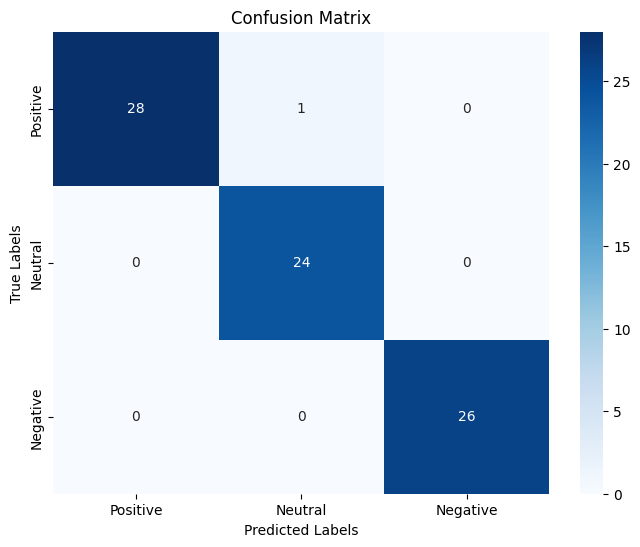

In [29]:
# TODO: Create a figure with size (8, 6)
# TODO: Plot confusion matrix using sns.heatmap()
# TODO: Set annot=True to display values in cells
# TODO: Use 'Blues' colormap and add axis labels
# TODO: Add title "Confusion Matrix"
# TODO: Display the plot using plt.show()

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=list(sentiment_labels.keys()), yticklabels=list(sentiment_labels.keys()))
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()

This walkthrough provided hands-on experience with deep learning for natural language processing, specifically sentiment analysis using LSTM networks, which is crucial for understanding customer feedback in retail environments.